<a href="https://colab.research.google.com/github/jpnoug/spectropy/blob/main/reponse_instrumentale_alpy_telluric_v2_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Courbe de réponse instrumentale — Alpy 600 / ISIS

**Mode d'emploi (Colab)** : *Exécution → Tout exécuter*. Deux fenêtres de téléchargement s'ouvrent à tour de rôle : d'abord ton spectre 1D ISIS non corrigé, puis le spectre de référence. Les profils calculés sont ensuite téléchargés automatiquement ; celui à utiliser dans ISIS est `…_reponse_telluric`. Une validation est faite automatiquement : ton spectre brut ÷ la réponse calculée, comparé à la référence.

**Principe (méthode de C. Buil).** Le spectre ISIS d'une étoile de référence, non corrigé de la réponse, s'écrit

`S(λ) = R(λ) · T(λ) · F_ref(λ)`

avec `R` la réponse (capteur + spectrographe + extinction continue), `T` la transmission tellurique (O₂, H₂O) et `F_ref` le spectre vrai de l'étoile (bibliothèque).

1. On dégrade `F_ref` à la résolution de l'Alpy (R ≈ 600).
2. `Q = S / F_ref` contient `R·T` plus les écarts de raies (Balmer, He I, …) entre l'étoile observée et la référence.
3. On **masque** les raies stellaires et les bandes telluriques, puis on **lisse** `Q` (lisseur de Whittaker en ln Q, écrêtage itératif des raies résiduelles). La courbe lissée est la **réponse propre `R`** ; elle interpole à travers les zones masquées.
4. Le **gabarit tellurique** est `T = Q / R` dans les bandes seulement (1 ailleurs).

**Application dans ISIS** : une seule division du spectre de la cible par `_reponse_telluric` (= R · T^α, avec α = `ALPHA_TELLURIQUE`). C'est suffisant si la cible est observée à une masse d'air et dans une humidité proches de la référence. Sinon, l'**étape 2** (dernière cellule, facultative, `FICHIER_CIBLE`) ajuste l'exposant de chaque bande sur la cible elle-même (O₂ ≈ rapport des masses d'air, H₂O libre) et écrit `…_reponse_telluric_opt` : toujours une seule division dans ISIS.

**Version 2 (novembre 2026)** : (1) fenêtres telluriques élargies (ailes des bandes H₂O à 6950–7050 et 7350–7420 Å, bande H₂O 7440–7585 Å), qui étaient auparavant absorbées par la réponse ; (2) lissage variable : période courte dans le bleu (`LISSAGE_BLEU_A`, 80 Å par défaut sous 4000 Å) pour suivre la forte courbure de la réponse autour de 3950 Å, période habituelle au-delà de 4600 Å, raccord progressif entre les deux ; (3) sorties rognées sous `LAM_SORTIE_MIN` (3600 Å) — l'ajustement utilise quand même les données jusqu'au bord bleu pour stabiliser la réponse à 3600 Å ; (4) au bord rouge, si la fin du spectre tombe dans une bande tellurique, la réponse est prolongée linéairement (en ln R) au lieu d'être tenue constante.

**Version 2.1 (novembre 2026)** : le lissage est désormais **fixé par défaut** (`LISSAGE_A = 200` Å) au lieu d'être choisi automatiquement. Le choix automatique par validation croisée ne sait pas distinguer la courbure de l'instrument des écarts de raies entre l'étoile observée et la référence : sur la campagne δ Cep il a retenu 100 Å une nuit et 400 Å la suivante, et la réponse à 100 Å avait absorbé les ailes de Hβ et de Hα (structures de 1 à 2 % ensuite reportées sur la cible). Pour une campagne, garde la **même valeur pour toutes les nuits**. Le mode `"auto"` reste disponible comme diagnostic, mais ne descend plus sous `LISSAGE_MIN_AUTO` (200 Å). Un nouveau contrôle signale si la réponse suit des raies stellaires (Hβ, He I 5876, Hα).

**Contrôles automatiques** : la plage des sorties est l'intersection du spectre non nul et du domaine de la référence (aucune extrapolation) ; la calibration en λ est vérifiée sur les raies de Balmer et un avertissement donne le décalage en Å si elle est à optimiser (`SEUIL_LAMBDA`).

La référence est normalisée à F(5556 Å) = 1 (convention ISIS), de sorte que la réponse garde l'échelle du spectre d'entrée (`NORMALISATION_REPONSE`). Trois fichiers sont produits (même format et même grille que le spectre d'entrée, .dat ou .fit) : réponse propre, gabarit tellurique, produit des deux.

*Limites à garder en tête* : (i) la réponse est interpolée à travers les zones masquées ; hors de la plage utilisable (spectre non nul, référence présente, bords rognés) elle n'est jamais extrapolée : elle vaut 0 comme ton spectre, ou le fichier est raccourci (`HORS_BORNES`) ; dans le bleu (< 4000 Å) les raies de Balmer se resserrent et les masques y laissent peu de continuum : regarde le résidu ; (ii) le gabarit tellurique n'est valable que si l'étalonnage en longueur d'onde de la cible est cohérent avec celui de l'étoile (un décalage de ~1 Å dans la bande A laisse des résidus) ; (iii) la réponse inclut l'extinction atmosphérique de la nuit à la masse d'air de l'étoile.

In [36]:
# ============================ PARAMÈTRES ============================
FICHIER_SPECTRE   = None   # None = fenêtre de téléchargement (Colab). Spectre 1D ISIS (.fit/.fits/.dat) : empilé, calibré en λ, tilt corrigé, SANS réponse
FICHIER_REFERENCE = None   # None = fenêtre de téléchargement. Miles, Pickles, ou fichier utilisateur (FITS 1D, table FITS, ou texte λ(Å) flux)
REF_MILIEU        = "air"               # "air" ou "vide" : milieu des λ de la référence (ISIS travaille en air)

R_INST        = 600     # résolution de l'Alpy utilisée pour dégrader la référence
REF_R_NATIVE  = None    # résolution native de la référence si connue (ex. 2200 pour Miles) ; None = ignorée

LAM_MIN, LAM_MAX = None, None   # bornes d'ajustement en Å (None = partout où le spectre est non nul ET la référence existe)
LAM_SORTIE_MIN   = 3600.        # Å : rien n'est écrit en deçà (fichiers rognés) ; l'ajustement utilise quand même les données plus bleues pour tenir le bord. None = pas de rognage
TRIM_BORD_A      = 20.          # Å retirés aux deux bords du spectre non nul (effets de bord ISIS)
ECHELLE_RAIES    = 1          # multiplie la largeur des masques de raies : 1 pour une B, 1.5 à 2 pour une A (ailes de Balmer plus larges)

LISSAGE_A         = 200.                         # Å, période de coupure du lissage (rouge / partie centrale). v2.1 : FIXE par défaut — garder la MÊME valeur pour toutes les nuits d'une campagne. "auto" = choix par validation croisée (diagnostic seulement)
LISSAGE_MIN_AUTO  = 200.                         # Å : en mode "auto", aucune période plus courte n'est retenue (en dessous, la réponse absorbe les ailes des raies de Balmer)
LISSAGE_BLEU_A    = 80.                          # période de coupure dans le bleu (Å) : la réponse y est très courbée (pic vers 3950 Å). None = lissage uniforme (ancien comportement)
TRANSITION_BLEU   = (4000., 4600.)               # Å : LISSAGE_BLEU_A sous la 1re borne, LISSAGE_A au-dessus de la 2nde, raccord progressif (log) entre les deux
LISSAGE_CANDIDATS = [200, 300, 400, 600]          # mode "auto" seulement ; les valeurs < LISSAGE_MIN_AUTO sont ignorées
SEUIL_EMPREINTE   = 0.8                          # % : au-delà, avertit que la réponse suit une raie stellaire (Hβ, He I 5876, Hα)
CLIP_BAS, CLIP_HAUT, N_ITER = 2.0, 3.0, 6        # écrêtage (en σ) des raies résiduelles, absorptions plus sévèrement
NORM_LAM  = (6630., 6645.)                       # plage de calage de la référence dans la validation (et de normalisation si NORMALISATION_REPONSE = 'un')
T_MIN     = 0.05                                 # plancher du gabarit tellurique (évite les divisions explosives)
ALPHA_TELLURIQUE = 1.0   # exposant du gabarit dans le fichier _reponse_telluric : 1 = même masse d'air que la cible
FORMAT_SORTIE = "auto"   # "auto" = même format ET même extension que le spectre d'entrée (.dat -> .dat, .fit -> .fit, .fits -> .fits) ; ou "dat", "fit", "fits", "both"
HORS_BORNES = "couper"   # jamais d'extrapolation hors de la plage utilisable (= spectre non nul ∩ domaine de la référence) : "couper" = fichiers limités à cette plage ; "zeros" = grille du spectre d'entrée conservée, réponse = 0 et gabarit = 1 hors plage
NORMALISATION_REPONSE = "entree"   # "entree" = échelle du spectre d'entrée (référence normalisée à 1 à LAM_NORM_REF, convention ISIS) ; "un" = réponse normalisée à 1 dans NORM_LAM
LAM_NORM_REF = 6640.     # Å : normalisation de la référence, F(LAM_NORM_REF) = 1
SEUIL_LAMBDA = 0.5       # Å : au-delà de ce décalage moyen sur les raies de Balmer, le notebook avertit que la calibration en λ est à optimiser
VITESSE_RADIALE = 0.0    # km/s : vitesse radiale héliocentrique de l'étoile observée (facultatif, sert au contrôle de la calibration en λ)
DECALAGE_ISIS_DEJA_APPLIQUE = 0.0   # Å : valeur du champ « Décalage spectral » d'ISIS (log du traitement) utilisée pour produire le spectre d'entrée ; 0 si aucune
REF_DECALAGE_A = 0.0     # Å : décalage appliqué aux λ de la référence avant usage (facultatif ; + = vers le rouge), si le contrôle montre qu'elle est décalée

PREFIXE_SORTIE = None    # None = nom du spectre d'entrée

# --- ÉTAPE 2 facultative : gabarit tellurique optimisé pour une cible (étoile observée après la référence) ---
FICHIER_CIBLE   = None   # None = étape sautée ; "demander" = fenêtre de téléchargement ; ou un nom de fichier (spectre ISIS brut de la cible, non corrigé)
MASSE_AIR_REF   = None   # facultatif : masse d'air de la référence ...
MASSE_AIR_CIBLE = None   # ... et de la cible. Si les deux sont donnés, l'exposant de départ pour O2 est X_cible / X_ref (sinon 1)
ALPHA_IMPOSE    = {}     # facultatif : forcer l'exposant d'une bande, ex. {"O2 A": 1.0}
LARGEUR_CONTINUUM_A = 25.   # Å de continuum utilisés de chaque côté d'une bande pour juger la correction

# --- validation facultative sur un second spectre (autre étoile, ou la même nuit) ---
FICHIER_TEST = None      # None = pas de validation ; "demander" = fenêtre de téléchargement ; ou un nom de fichier
REF_TEST     = None      # idem : référence de cette autre étoile (facultative), pour juger la correction

# ---- Raies masquées (air, Å) : (nom, centre, demi-largeur). Étoiles A et B. À éditer librement. ----
RAIES = [
    # Balmer, de Hα à H15 et limite. Demi-largeurs réglées sur une B2 IV à R≈600 (HD 216916) : serrées pour
    # garder du continuum dans le bleu, où la réponse est raide. Pour une A0-A2, monter ECHELLE_RAIES à 1.5-2.
    ("Halpha",6562.8,25), ("Hbeta",4861.3,20), ("Hgamma",4340.5,18), ("Hdelta",4101.7,16),
    ("Hepsilon",3970.1,13), ("Ca II K",3933.7,9), ("Ca II H",3968.5,9),
    ("H8",3889.1,11), ("H9",3835.4,10), ("H10",3797.9,9), ("H11",3770.6,9),
    ("H12-H15",3730.0,13), ("limite Balmer",3675.0,15),
    # Hélium (étoiles B)
    ("He I 4026",4026.2,15), ("He I 4144",4143.8,12), ("He I 4388",4387.9,12), ("He I 4471",4471.5,20),
    ("He I 4713",4713.1,12), ("He I 4922",4921.9,12), ("He I 5016",5015.7,12), ("He I 5876",5875.6,15),
    ("He I 6678",6678.2,12), ("He I 7065",7065.2,12), ("He II 4686",4685.7,15), ("He II 5412",5411.5,12),
    # Métaux et ions typiques B/A
    ("Mg II 4481",4481.2,20), ("Si III 4565",4565.0,20), ("C II 4267",4267.3,12),
    ("Si II 6347",6347.1,12), ("Si II 6371",6371.4,12), ("Na D",5893.0,15), ("O I 7774",7774.0,15),
    # Bandes diffuses interstellaires
    ("DIB 4430",4430.0,25), ("DIB 5780",5780.5,10), ("DIB 5797",5797.1,8), ("DIB 6284",6283.9,12), ("DIB 6613",6613.6,8),
    # Rouge lointain (ignorées si hors du spectre)
    ("Ca II 8498",8498.0,20), ("Ca II 8542",8542.1,20), ("Ca II 8662",8662.1,20),
    ("Pa 8438",8437.9,15), ("Pa 8467",8467.3,15), ("Pa 8502",8502.5,15), ("Pa 8545",8545.4,15),
    ("Pa 8598",8598.4,15), ("Pa 8665",8665.0,15), ("Pa 8750",8750.5,15), ("Pa 8863",8862.8,15),
]
# ---- Fenêtres telluriques (Å) : exclues de l'ajustement de R, et utilisées pour le gabarit T ----
# Élargies en v2 : les ailes H2O (6950-7050 Å avec la bande B, 7350-7420 Å avec la bande 7200) et la bande faible 7440-7585 Å
# étaient auparavant absorbées par la réponse (creux de 3-4 % dans R). Bande O2 B fusionnée avec l'aile H2O voisine.
FENETRES_TELL = [("O2 B + H2O",6855.,7050.), ("H2O 7200",7140.,7420.), ("H2O 7500",7440.,7585.), ("O2 A",7585.,7710.), ("H2O 8200",8110.,8380.)]
RAMPE_TELL = 10.   # raccord progressif (Å) entre T = 1 et le gabarit mesuré, aux bords des fenêtres

In [37]:
# ============================ OUTILS ============================
import os
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.linalg import spsolve
from scipy.ndimage import gaussian_filter1d
from astropy.io import fits

def trouver(nom, invite=""):
    # Renvoie le nom d'un fichier présent ; sinon, dans Colab, ouvre la fenêtre de téléchargement.
    if nom and os.path.exists(nom):
        return nom
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(nom or invite)
    print(invite or f"Sélectionne le fichier « {nom} » :")
    recu = files.upload()
    if not recu:
        raise RuntimeError("Aucun fichier reçu.")
    return list(recu.keys())[0]

def lire_1d(chemin):
    # Renvoie (lam en Å, flux, en-tête ou None). FITS 1D (CRVAL1/CDELT1), table FITS, ou texte.
    chemin = trouver(chemin)
    if os.path.splitext(chemin)[1].lower() in ('.fit', '.fits', '.fts'):
        with fits.open(chemin) as h:
            for x in h:
                if isinstance(x, fits.BinTableHDU):
                    noms = [c.upper() for c in x.columns.names]
                    a = noms.index('WAVELENGTH') if 'WAVELENGTH' in noms else 0
                    b = noms.index('FLUX') if 'FLUX' in noms else 1
                    return (np.array(x.data.field(a), float), np.array(x.data.field(b), float), None)
            hdu = next(x for x in h if x.data is not None and np.ndim(x.data) >= 1)
            flux = np.squeeze(np.array(hdu.data, dtype=float))
            hdr = hdu.header.copy()
        if flux.ndim != 1:
            raise ValueError("Le fichier FITS doit contenir un spectre 1D.")
        crval = hdr.get('CRVAL1'); cdelt = hdr.get('CDELT1', hdr.get('CD1_1')); crpix = hdr.get('CRPIX1', 1.0)
        if crval is None or cdelt is None:
            raise ValueError("CRVAL1 / CDELT1 absents de l'en-tête : calibration en λ introuvable.")
        lam = crval + (np.arange(flux.size) + 1 - crpix) * cdelt
        if hdr.get('DC-FLAG', 0) == 1:
            lam = 10 ** lam
        u = str(hdr.get('CUNIT1', 'angstrom')).strip().lower()
        lam = lam * {'nm': 10., 'um': 1e4, 'micron': 1e4, 'm': 1e10}.get(u, 1.)
        return lam, flux, hdr
    lignes = []
    for l in open(chemin):
        l = l.strip().replace(',', ' ').replace(';', ' ')
        if not l or l[0] in '#%':
            continue
        p = l.split()
        try:
            lignes.append((float(p[0]), float(p[1])))
        except (ValueError, IndexError):
            pass
    d = np.array(lignes)
    return d[:, 0], d[:, 1], None

def air_depuis_vide(lv):
    s2 = (1e4 / lv) ** 2
    n = 1 + 6.4328e-5 + 2.94981e-2 / (146 - s2) + 2.5540e-4 / (41 - s2)
    return lv / n

def degrader(lam, flux, R, R_native=None):
    # Convolution gaussienne à R constant (noyau de largeur constante en ln λ).
    sig = 1.0 / (R * 2.3548)
    if R_native:
        s2 = sig ** 2 - (1.0 / (R_native * 2.3548)) ** 2
        if s2 <= 0:
            return flux
        sig = np.sqrt(s2)
    l = np.log(lam); pas = sig / 5.0
    g = np.arange(l[0], l[-1], pas)
    f = gaussian_filter1d(np.interp(g, l, flux), sigma=5.0, mode='nearest')
    return np.interp(l, g, f)

def zones(lam, m):
    d = np.flatnonzero(np.diff(np.r_[0, m.astype(int), 0]))
    return [(lam[i], lam[j - 1]) for i, j in zip(d[::2], d[1::2])]

def masque_raies(lam, raies, echelle, R):
    m = np.zeros(lam.size, bool)
    for _, l0, demi in raies:
        m |= np.abs(lam - l0) <= max(demi * echelle, 1.5 * l0 / R)   # jamais plus étroit que ~1,5 FWHM instrumentale
    return m

def fenetre_douce(lam, a, b, rampe):
    w = np.ones(lam.size)
    g = lam < a; w[g] = 0.5 * (1 + np.cos(np.pi * np.clip((a - lam[g]) / rampe, 0, 1)))
    d = lam > b; w[d] = 0.5 * (1 + np.cos(np.pi * np.clip((lam[d] - b) / rampe, 0, 1)))
    return w

def whittaker(y, w, lw):
    # lw scalaire (lissage uniforme) ou tableau de même taille que y (lissage variable en λ)
    n = y.size
    D = sp.diags([1., -2., 1.], [0, 1, 2], shape=(n - 2, n), format='csc')
    pen = lw * (D.T @ D) if np.isscalar(lw) else D.T @ sp.diags(np.asarray(lw)[1:-1]) @ D
    A = (sp.diags(w, format='csc') + pen).tocsc()
    return spsolve(A, w * y)

def lw_depuis_periode(L_A, dlam):
    return ((L_A / dlam) / (2 * np.pi)) ** 4     # période de coupure à mi-gain, en Å (scalaire ou tableau)

def periode_locale(lam, L_A):
    # Période de coupure en fonction de λ : LISSAGE_BLEU_A sous TRANSITION_BLEU[0], L_A au-dessus de TRANSITION_BLEU[1].
    if not LISSAGE_BLEU_A or LISSAGE_BLEU_A >= L_A:
        return np.full(lam.size, float(L_A))
    l1, l2 = TRANSITION_BLEU
    t = np.clip((lam - l1) / (l2 - l1), 0., 1.); t = 0.5 - 0.5 * np.cos(np.pi * t)
    return np.exp(np.log(LISSAGE_BLEU_A) + (np.log(L_A) - np.log(LISSAGE_BLEU_A)) * t)

def ajuster(logQ, w0, L_A, dlam):
    lw = lw_depuis_periode(periode_locale(lam, L_A), dlam); w = w0.copy(); bons = w0 > 0
    for _ in range(N_ITER):
        z = whittaker(logQ, w, lw)
        r = logQ - z
        sig = 1.4826 * np.median(np.abs(r[bons] - np.median(r[bons])))
        w = w0 * ((r > -CLIP_BAS * sig) & (r < CLIP_HAUT * sig))
    return z, w, sig

def cv_lissage(lam, logQ, w0, candidats, dlam, bloc=120.):
    # Validation croisée par blocs : on retire un bloc de `bloc` Å et on mesure l'erreur d'interpolation.
    bords = np.arange(lam[0], lam[-1] + bloc, bloc); res = {}
    for L in candidats:
        lw = lw_depuis_periode(periode_locale(lam, L), dlam); err = []
        for k, (a, b) in enumerate(zip(bords[:-1], bords[1:])):
            if k == 0 or k == len(bords) - 2:
                continue
            blk = (lam >= a) & (lam < b); test = blk & (w0 > 0)
            if test.sum() < 5:
                continue
            z = whittaker(logQ, w0 * (~blk), lw)
            err.append(logQ[test] - z[test])
        e2 = np.sort(np.concatenate(err) ** 2)
        res[L] = float(np.sqrt(np.mean(e2[: int(0.95 * e2.size)])))
    return res

BALMER = [("Halpha", 6562.8, 48.), ("Hbeta", 4861.3, 40.), ("Hgamma", 4340.5, 34.), ("Hdelta", 4101.7, 29.)]   # (nom, λ air Å, demi-fenêtre d'ajustement Å)

def centre_raie(lam, y, l0, W):
    # Centre (Å) d'une raie d'absorption : gaussienne + continuum linéaire sur |λ − l0| ≤ W. None si fenêtre incomplète ou raie non détectée.
    from scipy.optimize import curve_fit
    m = np.abs(lam - l0) <= W
    dl = float(np.median(np.diff(lam)))
    if m.sum() < 0.9 * (2 * W / dl) or not np.all(np.isfinite(y[m])):
        return None
    x = lam[m]; v = y[m] / np.median(y[m])
    f = lambda x, a, c, s, b, p: b + p * (x - l0) - a * np.exp(-0.5 * ((x - c) / s) ** 2)
    try:
        p, _ = curve_fit(f, x, v, p0=[0.25, l0, 8., 1., 0.],
                         bounds=([0., l0 - 8, 3., 0., -np.inf], [np.inf, l0 + 8, 40., np.inf, np.inf]))
    except Exception:
        return None
    if p[0] < 0.03 or abs(p[1] - l0) > 7.9:          # raie non détectée, ou centre collé à la borne de recherche
        return None
    return float(p[1])

def controle_lambda(lam, obs, ref, seuil=0.5, rv=0.0, v_hel=None, deja=0.0, tracer=True):
    # Mesure le centre des raies de Balmer dans le spectre corrigé (obs) et dans la référence (ref), et le compare aux longueurs d'onde de laboratoire.
    c = 299792.458; res = []
    for nom, l0, W in BALMER:
        co = centre_raie(lam, obs, l0, W)
        if co is None:
            continue
        cr = centre_raie(lam, ref, l0, W)
        res.append((nom, l0, W, co, cr))
    if not res:
        print("Contrôle de la calibration en λ impossible : aucune raie de Balmer (Hα–Hδ) entièrement dans la plage utilisable et détectée.")
        return None
    attendu = lambda l0: l0 * (1 + rv / c)
    do = np.array([r[3] - attendu(r[1]) for r in res])
    dr = np.array([(r[4] - r[1]) if r[4] is not None else np.nan for r in res])
    print("Contrôle de la calibration en λ : centre des raies de Balmer, mesuré − longueur d'onde de laboratoire (air) ; + = trop rouge")
    print(f"   {'raie':8s} {'λ labo':>8s} {'spectre':>9s} {'référence':>10s}")
    for (nom, l0, W, co, cr), a, b in zip(res, do, dr):
        print(f"   {nom:8s} {l0:8.1f} {a:+8.2f} Å {b:+9.2f} Å" if np.isfinite(b) else f"   {nom:8s} {l0:8.1f} {a:+8.2f} Å {'—':>10s}")
    moy = float(np.mean(do)); etendue = float(np.ptp(do)) if do.size > 1 else 0.0; lmoy = float(np.mean([r[1] for r in res]))
    if abs(moy) <= seuil and etendue <= 2 * seuil:
        print(f"   ✔ Spectre : décalage moyen {moy:+.2f} Å (seuil {seuil:.1f} Å) : calibration en λ cohérente avec les raies de Balmer.")
    elif etendue > 2 * seuil:
        print(f"   ⚠ Spectre : les décalages vont de {do.min():+.2f} à {do.max():+.2f} Å selon la raie (moyenne {moy:+.2f} Å) : plutôt une erreur d'échelle (polynôme de dispersion) qu'un simple décalage du zéro → calibration à optimiser.")
    else:
        print(f"   ⚠ Spectre : décalage moyen {moy:+.2f} Å ({c * moy / lmoy:+.0f} km/s) > {seuil:.1f} Å : calibration en λ à optimiser (décaler le zéro d'environ {-moy:+.2f} Å).")
    if np.isfinite(dr).any():
        mr = float(np.nanmean(dr))
        if abs(mr) > seuil:
            print(f"   ⚠ Référence : décalage moyen {mr:+.2f} Å par rapport au laboratoire : vérifie REF_MILIEU (air/vide ≈ 1,4 Å à Hβ), la vitesse radiale incluse dans la référence, ou corrige-la avec REF_DECALAGE_A = {-mr:+.1f}.")
        else:
            print(f"   ✔ Référence : décalage moyen {mr:+.2f} Å.")
    if etendue > 2 * seuil:
        print("   → Valeur à renseigner dans ISIS : aucune valeur unique (les décalages varient d'une raie à l'autre) ; vérifie le polynôme / la lampe d'étalonnage.")
    else:
        v = round(deja - moy, 1)
        if abs(moy) <= seuil:
            print(f"   → Décalage spectral à renseigner dans ISIS : {v + 0.0:+.1f} Å (champ « Décalage spectral » ; actuellement {deja:+.1f}) : aucune correction nécessaire.")
        else:
            print(f"   → Décalage spectral à renseigner dans ISIS : {v + 0.0:+.1f} Å (champ « Décalage spectral » ; actuellement {deja:+.1f}). Puis refais le spectre brut dans ISIS et relance ce notebook : le décalage moyen doit devenir proche de 0 (±{seuil:.1f} Å).")
    note = f"   Le décalage du spectre inclut la vitesse radiale réelle de l'étoile (réglée ici sur {rv:+.0f} km/s : VITESSE_RADIALE)"
    if v_hel is not None:
        note += f" et la correction héliocentrique (BSS_VHEL = {v_hel} km/s dans l'en-tête ; la Terre apporte jusqu'à ±0,5 Å à Hβ)"
    print(note + ".")
    if tracer:
        fig, axs = plt.subplots(1, len(res), figsize=(3.1 * len(res), 2.8), squeeze=False)
        for ax, (nom, l0, W, co, cr) in zip(axs[0], res):
            m = np.abs(lam - l0) <= W + 15
            ax.plot(lam[m], obs[m] / np.nanmedian(obs[m]), color='k', lw=.8, label="spectre")
            ax.plot(lam[m], ref[m] / np.nanmedian(ref[m]), color='tab:red', lw=1, label="référence")
            ax.axvline(attendu(l0), color='0.6', lw=1, label="labo")
            ax.axvline(co, color='k', lw=.8, ls='--')
            if cr is not None:
                ax.axvline(cr, color='tab:red', lw=.8, ls='--')
            ax.set_title(nom, fontsize=9); ax.legend(fontsize=6)
        plt.tight_layout(); plt.show()
    return moy

def formats_sortie(ext_entree, choix):
    ext_fits = ext_entree if ext_entree in ('fit', 'fits', 'fts') else 'fit'
    return {'auto': [ext_entree], 'dat': ['dat'], 'fit': ['fit'], 'fits': ['fits'], 'both': ['dat', ext_fits]}[choix]

def entete_synthetique(lam, dlam):
    h = fits.Header()
    h['CRVAL1'] = float(lam[0]); h['CDELT1'] = float(dlam); h['CRPIX1'] = 1.0
    h['CTYPE1'] = 'Wavelength'; h['CUNIT1'] = 'Angstrom'
    return h

def ecrire_dat(chemin, lam, y):
    # Même style que les .dat ISIS : deux colonnes, fins de ligne CRLF.
    with open(chemin, 'w', newline='') as f:
        for a, b in zip(lam, y):
            f.write(f"{a:.4f} {b:.6g}\r\n")
    return chemin

def ecrire_fits(chemin, data, hdr, notes, crval=None):
    h = hdr.copy()
    if crval is not None:                  # fichier raccourci : nouveau point de départ de la grille
        h['CRVAL1'] = float(crval); h['CRPIX1'] = 1.0
    for k in ('BZERO', 'BSCALE', 'BLANK'):
        h.remove(k, ignore_missing=True)
    for n in notes:
        h['HISTORY'] = n
    fits.PrimaryHDU(np.asarray(data, np.float32), header=h).writeto(chemin, overwrite=True)
    return chemin

▶ 1/2 — Choisis le spectre 1D ISIS NON corrigé de la réponse instrumentale (.fit / .fits / .dat) :


Saving _hd_216916_0922_20260922_808.fits to _hd_216916_0922_20260922_808 (3).fits
Spectre : 2887.0–7674.0 Å, pas 0.500 Å/pix, 9575 points (non nul : 2925.0–7640.5 Å)
  DATE-OBS  = 2026-09-22T19:23:50
  EXPTIME   = 304
  SPE_RPOW  = 503
  BSS_ITRP  = 503
▶ 2/2 — Choisis le spectre de référence (Miles, Pickles, ou le tien ; FITS 1D ou texte) :


Saving ref_HD216916_pickles_corr.fits to ref_HD216916_pickles_corr (3).fits
Référence : 3500.0–8000.0 Å


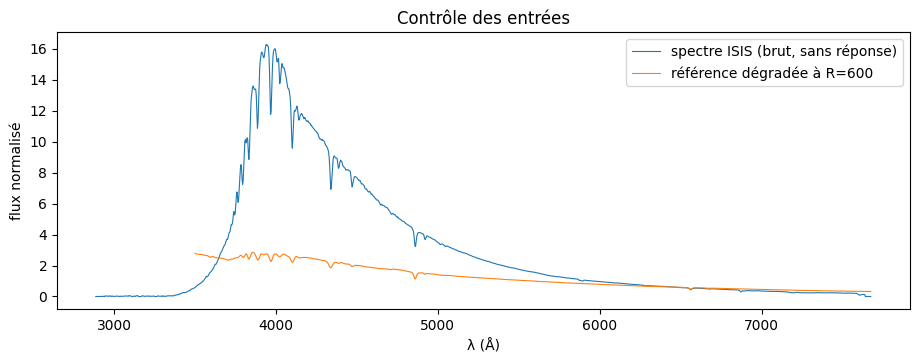

In [38]:
# ============================ LECTURE ============================
FICHIER_SPECTRE = trouver(FICHIER_SPECTRE, "▶ 1/2 — Choisis le spectre 1D ISIS NON corrigé de la réponse instrumentale (.fit / .fits / .dat) :")
lam, S, hdr = lire_1d(FICHIER_SPECTRE)
ext_entree = os.path.splitext(FICHIER_SPECTRE)[1].lower().lstrip('.')
if ext_entree not in ('fit', 'fits', 'fts'):
    ext_entree = 'dat'                                  # .dat / .txt : sortie en texte ; un FITS (même table) donne un FITS de même extension
dlam = float(np.median(np.diff(lam)))
if not np.allclose(np.diff(lam), dlam, rtol=2e-3):
    raise ValueError("Grille en λ non linéaire : rééchantillonner linéairement (ISIS) avant.")
nn = np.flatnonzero(np.isfinite(S) & (S != 0))
print(f"Spectre : {lam[0]:.1f}–{lam[-1]:.1f} Å, pas {dlam:.3f} Å/pix, {lam.size} points (non nul : {lam[nn[0]]:.1f}–{lam[nn[-1]]:.1f} Å)")
if hdr is None:
    hdr = entete_synthetique(lam, dlam)
for k in ('OBJECT', 'DATE-OBS', 'EXPTIME', 'AIRMASS', 'SECZ', 'SPE_RPOW', 'BSS_ITRP', 'TELESCOP', 'INSTRUME'):
    if k in hdr:
        print(f"  {k:9s} = {hdr[k]}")

FICHIER_REFERENCE = trouver(FICHIER_REFERENCE, "▶ 2/2 — Choisis le spectre de référence (Miles, Pickles, ou le tien ; FITS 1D ou texte) :")
lam_r, F_r, _ = lire_1d(FICHIER_REFERENCE)
ok = np.isfinite(lam_r) & np.isfinite(F_r)
lam_r, F_r = lam_r[ok], F_r[ok]
o = np.argsort(lam_r); lam_r, F_r = lam_r[o], F_r[o]
if REF_MILIEU.lower().startswith('v'):
    lam_r = air_depuis_vide(lam_r)
lam_r = lam_r + REF_DECALAGE_A
print(f"Référence : {lam_r[0]:.1f}–{lam_r[-1]:.1f} Å" + (f" (décalée de {REF_DECALAGE_A:+.2f} Å)" if REF_DECALAGE_A else ""))
F_deg = degrader(lam_r, F_r, R_INST, REF_R_NATIVE)
Fref = np.interp(lam, lam_r, F_deg, left=np.nan, right=np.nan)

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(lam, S / np.nanmedian(S), lw=.8, label="spectre ISIS (brut, sans réponse)")
ax.plot(lam, Fref / np.nanmedian(Fref), lw=.8, label=f"référence dégradée à R={R_INST}")
ax.set_xlabel("λ (Å)"); ax.set_ylabel("flux normalisé"); ax.legend(); ax.set_title("Contrôle des entrées")
plt.show()

Référence normalisée à 1 à 6640 Å : la réponse garde l'échelle du spectre d'entrée.
Points d'ajustement : 4907 / 8202 valides (40 % masqués)
Lissage : période de coupure 80 Å sous 4000 Å, 200 Å au-delà de 4600 Å ; dispersion des résidus 0.61 %
   Mode de lissage : fixe
Contrôle d'empreinte (écart local max. à une réponse 2× plus lisse) : Hbeta 2.70 % ; He I 5876 0.52 % ; Halpha 0.64 %
   ⚠ La réponse suit la raie Hbeta (> 0.8 %) : augmente LISSAGE_A ou élargis les masques (ECHELLE_RAIES).
Domaine du spectre non nul : 2932.5–7640.5 Å ; domaine de la référence : 3500.0–8000.0 Å
Plage utilisable (intersection, bords rognés) : 3600.0–7620.5 Å ; hors plage, aucune extrapolation.
   Attention : de 7440 à 7620 Å (bord rouge, dans une bande tellurique) la réponse n'est plus contrainte par des points hors bande ; elle y est prolongée linéairement (en ln R) sur 181 Å : flux moins sûr dans cette zone.
Continuum bleu, Q / R − 1 sur les points retenus (moyenne ± dispersion, par 100 Å) :
    3600– 3

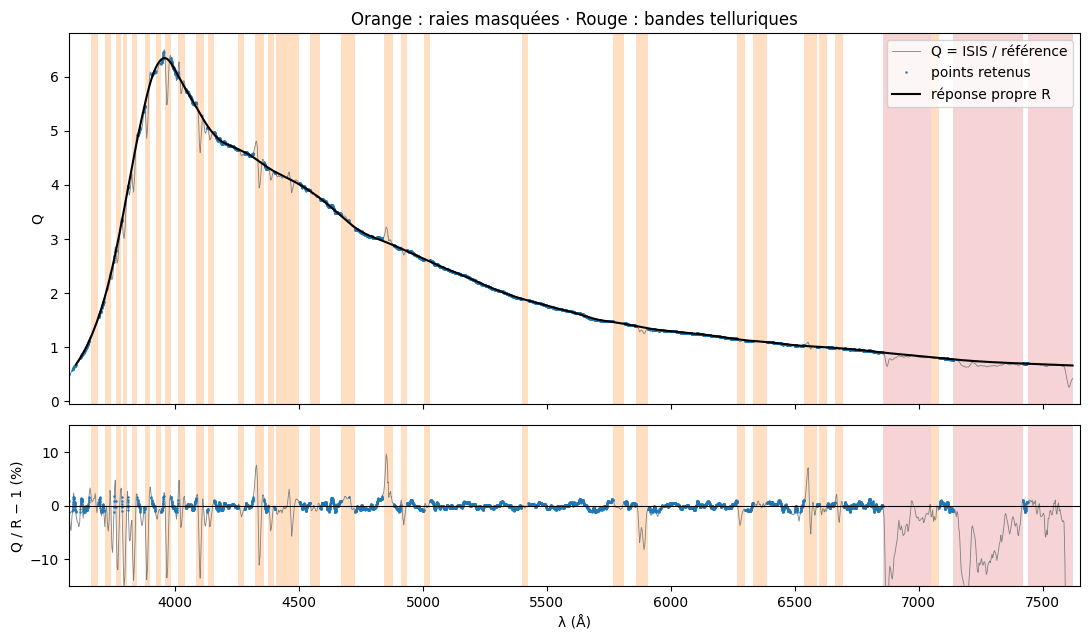

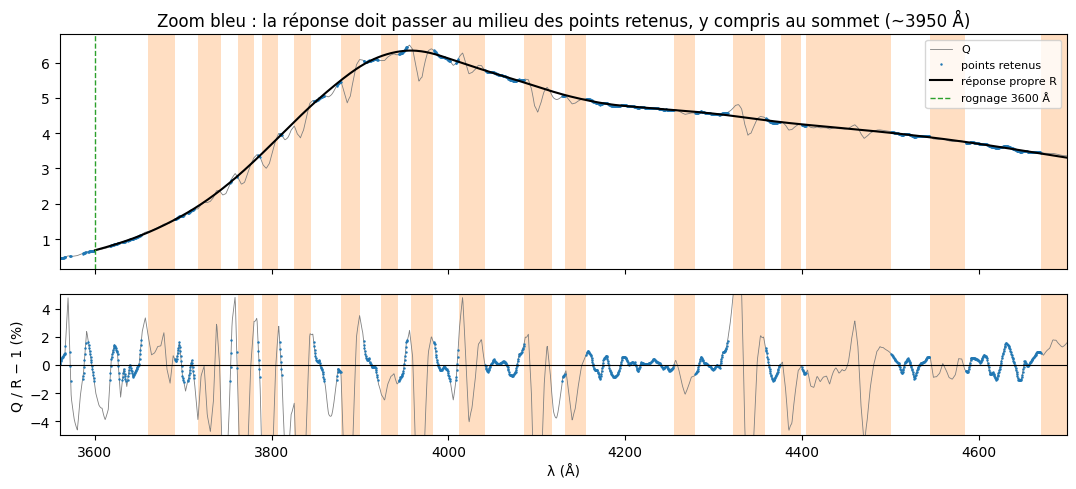

In [39]:
# ============================ RÉPONSE PROPRE ============================
if NORMALISATION_REPONSE == "entree":
    ech = np.nanmedian(Fref[np.abs(lam - LAM_NORM_REF) <= 20])
    if not np.isfinite(ech) or ech <= 0:
        raise ValueError("Référence absente autour de LAM_NORM_REF : change LAM_NORM_REF ou mets NORMALISATION_REPONSE = 'un'.")
    Fref = Fref / ech
    print(f"Référence normalisée à 1 à {LAM_NORM_REF:.0f} Å : la réponse garde l'échelle du spectre d'entrée.")

with np.errstate(all='ignore'):
    non_nul = np.flatnonzero(np.isfinite(S) & (S > 0))
    trim = int(round(TRIM_BORD_A / dlam))
    bord = np.zeros(lam.size, bool); bord[non_nul[0] + trim: non_nul[-1] - trim + 1] = True
    valide = np.isfinite(S) & np.isfinite(Fref) & (S > 0) & (Fref > 0) & bord
    valide &= (lam >= lam_r[0] + TRIM_BORD_A) & (lam <= lam_r[-1] - TRIM_BORD_A)      # jamais au-delà du domaine de la référence (bords de la convolution rognés)
    if LAM_MIN: valide &= lam >= LAM_MIN
    if LAM_MAX: valide &= lam <= LAM_MAX
    Q = np.where(valide, S / np.where(valide, Fref, 1.), np.nan)
    logQ = np.where(valide, np.log(np.where(valide, Q, 1.)), 0.)

m_raies = masque_raies(lam, RAIES, ECHELLE_RAIES, R_INST)
m_tell = np.zeros(lam.size, bool)
for _, a, b in FENETRES_TELL:
    m_tell |= (lam >= a) & (lam <= b)
w0 = (valide & ~m_raies & ~m_tell).astype(float)
print(f"Points d'ajustement : {int(w0.sum())} / {int(valide.sum())} valides "
      f"({100 * (1 - w0.sum() / valide.sum()):.0f} % masqués)")

_, w_pre, _ = ajuster(logQ, w0, 200., dlam)
MODE_LISSAGE = "auto" if str(LISSAGE_A).lower() == 'auto' else "fixe"
if MODE_LISSAGE == "auto":
    cands = [L for L in LISSAGE_CANDIDATS if L >= (LISSAGE_MIN_AUTO or 0)]
    if not cands:
        raise ValueError(f"Aucune période candidate ≥ LISSAGE_MIN_AUTO = {LISSAGE_MIN_AUTO} Å dans LISSAGE_CANDIDATS.")
    ecartees = sorted(set(LISSAGE_CANDIDATS) - set(cands))
    if ecartees:
        print(f"Mode auto : périodes {ecartees} Å ignorées (< LISSAGE_MIN_AUTO = {LISSAGE_MIN_AUTO:.0f} Å).")
    cv = cv_lissage(lam, logQ, w_pre, cands, dlam)
    cmin = min(cv.values())
    L_A = max(L for L, v in cv.items() if v <= 1.03 * cmin)    # le plus lisse parmi les ex æquo à 3 % (v2 : 10 % retenait des périodes trop longues, biais de continuum ±0,25 %)
    print("Validation croisée (erreur d'interpolation à travers un trou de 120 Å) :")
    for L, v in cv.items():
        print(f"   période {L:4d} Å : {100 * v:.2f} %" + ("   <-- retenue" if L == L_A else ""))
    print(f"   ⚠ Mode auto : la période peut changer d'une nuit à l'autre. Pour une campagne, fixe LISSAGE_A = {L_A:.0f} (ou 200) pour TOUTES les nuits.")
else:
    L_A = float(LISSAGE_A)
    if LISSAGE_MIN_AUTO and L_A < LISSAGE_MIN_AUTO:
        print(f"   ⚠ LISSAGE_A = {L_A:.0f} Å < {LISSAGE_MIN_AUTO:.0f} Å : risque que la réponse absorbe les ailes des raies de Balmer (voir le contrôle d'empreinte ci-dessous).")

z, w_fin, sig = ajuster(logQ, w0, L_A, dlam)
b = np.flatnonzero(w_fin > 0); ia, ib = b[0], b[-1]
# Au-delà du dernier point retenu, le lisseur de Whittaker (pénalité de dérivée seconde) prolonge ln R linéairement :
# c'est conservé (v2) au lieu de tenir R constant, ce qui négligeait la pente de la réponse dans les bandes telluriques de bord.
v = np.flatnonzero(valide); i_lo, i_hi = v[0], v[-1]
if LAM_SORTIE_MIN:
    i_lo = max(i_lo, int(np.searchsorted(lam, LAM_SORTIE_MIN)))     # rognage bleu des sorties (l'ajustement a utilisé les données plus bleues)
usable = np.zeros(lam.size, bool); usable[i_lo:i_hi + 1] = True
if LISSAGE_BLEU_A and LISSAGE_BLEU_A < L_A:
    print(f"Lissage : période de coupure {LISSAGE_BLEU_A:.0f} Å sous {TRANSITION_BLEU[0]:.0f} Å, {L_A:.0f} Å au-delà de {TRANSITION_BLEU[1]:.0f} Å ; dispersion des résidus {100 * sig:.2f} %")
else:
    print(f"Lissage : période de coupure {L_A:.0f} Å ; dispersion des résidus {100 * sig:.2f} %")
print(f"   Mode de lissage : {MODE_LISSAGE}")

# Contrôle d'empreinte stellaire (v2.1) : la réponse ne doit pas suivre les raies de l'étoile.
# On la compare à une version deux fois plus lisse (au moins 400 Å) autour des raies fortes : dans cette région
# (4400–6850 Å) la vraie réponse est lisse, un écart local signale des ailes de raies absorbées par le lissage.
z_lisse = ajuster(logQ, w0, max(2. * L_A, 400.), dlam)[0]
EMPREINTE = {}
for nom_, l0_, dw_ in [("Hbeta", 4861.3, 120.), ("He I 5876", 5876., 80.), ("Halpha", 6562.8, 120.)]:
    k_ = valide & (lam >= l0_ - dw_) & (lam <= l0_ + dw_)
    if k_.sum() > 10:
        d_ = 100 * (np.exp(z[k_] - z_lisse[k_]) - 1)
        d_ -= np.median(100 * (np.exp(z[valide & (np.abs(lam - l0_) < 300)] - z_lisse[valide & (np.abs(lam - l0_) < 300)]) - 1))
        EMPREINTE[nom_] = float(np.max(np.abs(d_)))
if EMPREINTE:
    print("Contrôle d'empreinte (écart local max. à une réponse 2× plus lisse) : " + " ; ".join(f"{n_} {v_:.2f} %" for n_, v_ in EMPREINTE.items()))
    pires = [n_ for n_, v_ in EMPREINTE.items() if v_ > SEUIL_EMPREINTE]
    if pires:
        print(f"   ⚠ La réponse suit la raie {', '.join(pires)} (> {SEUIL_EMPREINTE} %) : augmente LISSAGE_A ou élargis les masques (ECHELLE_RAIES).")
    else:
        print(f"   OK : aucune empreinte de raie stellaire > {SEUIL_EMPREINTE} %.")
print(f"Domaine du spectre non nul : {lam[non_nul[0]]:.1f}–{lam[non_nul[-1]]:.1f} Å ; domaine de la référence : {lam_r[0]:.1f}–{lam_r[-1]:.1f} Å")
print(f"Plage utilisable (intersection, bords rognés) : {lam[i_lo]:.1f}–{lam[i_hi]:.1f} Å ; hors plage, aucune extrapolation.")
if lam[i_hi] - lam[ib] > 2 * dlam:
    print(f"   Attention : de {lam[ib]:.0f} à {lam[i_hi]:.0f} Å (bord rouge, dans une bande tellurique) la réponse n'est plus contrainte par des points "
          f"hors bande ; elle y est prolongée linéairement (en ln R) sur {lam[i_hi] - lam[ib]:.0f} Å : flux moins sûr dans cette zone.")
if lam[ia] > lam[i_lo] + 2 * dlam:
    print(f"   Attention : de {lam[i_lo]:.0f} à {lam[ia]:.0f} Å (bord bleu) la réponse est prolongée linéairement (en ln R), sans point d'ajustement.")

# Biais résiduel du continuum dans le bleu (points retenus, par tranches de 100 Å) : doit rester < ~0,5 %
with np.errstate(all='ignore'):
    rc = 100 * (np.exp(logQ - z) - 1)
lignes_b = []
for a in np.arange(np.floor(lam[i_lo] / 100) * 100, 4700., 100.):
    q = (w_fin > 0) & (lam >= max(a, lam[i_lo])) & (lam < a + 100)
    if q.sum() >= 10:
        lignes_b.append((a, float(np.mean(rc[q])), float(np.std(rc[q]))))
if lignes_b:
    print("Continuum bleu, Q / R − 1 sur les points retenus (moyenne ± dispersion, par 100 Å) :")
    for a, mo, sd in lignes_b:
        print(f"   {a:5.0f}–{a + 100:5.0f} Å : {mo:+.2f} % ± {sd:.2f} %" + ("   ⚠ biais > 0,5 % : réduire LISSAGE_BLEU_A" if abs(mo) > 0.5 else ""))

Rfit = np.exp(z)
sel = (lam >= NORM_LAM[0]) & (lam <= NORM_LAM[1]) & valide
if NORMALISATION_REPONSE == "entree":
    Rnorm = Rfit                                   # échelle du spectre d'entrée (référence normalisée à F(5556) = 1)
else:
    Rnorm = Rfit / (np.median(Rfit[sel]) if sel.any() else np.median(Rfit[valide]))

def ombrer(ax):
    for a, b2 in zones(lam, m_raies & valide): ax.axvspan(a, b2, color='tab:orange', alpha=.25, lw=0)
    for a, b2 in zones(lam, m_tell & valide): ax.axvspan(a, b2, color='tab:red', alpha=.2, lw=0)

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={'height_ratios': [3, 1.3]})
a1.plot(lam, Q, lw=.6, color='0.5', label="Q = ISIS / référence")
a1.plot(lam[w_fin > 0], Q[w_fin > 0], '.', ms=1.5, color='tab:blue', label="points retenus")
a1.plot(lam[usable], Rfit[usable], color='k', lw=1.5, label="réponse propre R")
ombrer(a1); a1.set_xlim(lam[i_lo] - 30, lam[i_hi] + 30); a1.set_ylabel("Q"); a1.legend(loc='upper right'); a1.set_title("Orange : raies masquées · Rouge : bandes telluriques")
res = 100 * (Q / Rfit - 1)
a2.plot(lam, res, lw=.6, color='0.5'); a2.plot(lam[w_fin > 0], res[w_fin > 0], '.', ms=1.5, color='tab:blue')
a2.axhline(0, color='k', lw=.8); ombrer(a2)
a2.set_ylim(-max(15, 6 * 100 * sig), max(15, 6 * 100 * sig)); a2.set_ylabel("Q / R − 1 (%)"); a2.set_xlabel("λ (Å)")
plt.tight_layout(); plt.show()

# Zoom bleu : suivi de la courbure de la réponse
zb = (lam >= lam[i_lo] - 40) & (lam <= 4700)
if zb.any():
    fig, (b1, b2) = plt.subplots(2, 1, figsize=(11, 5), sharex=True, gridspec_kw={'height_ratios': [2, 1.2]})
    b1.plot(lam[zb], Q[zb], lw=.6, color='0.5', label="Q")
    k_ = zb & (w_fin > 0); b1.plot(lam[k_], Q[k_], '.', ms=1.5, color='tab:blue', label="points retenus")
    b1.plot(lam[zb & usable], Rfit[zb & usable], color='k', lw=1.5, label="réponse propre R")
    if LAM_SORTIE_MIN: b1.axvline(LAM_SORTIE_MIN, color='tab:green', lw=1, ls='--', label=f"rognage {LAM_SORTIE_MIN:.0f} Å")
    ombrer(b1); b1.legend(fontsize=8); b1.set_title("Zoom bleu : la réponse doit passer au milieu des points retenus, y compris au sommet (~3950 Å)")
    b2.plot(lam[zb], res[zb], lw=.6, color='0.5'); b2.plot(lam[k_], res[k_], '.', ms=1.5, color='tab:blue')
    b2.axhline(0, color='k', lw=.8); ombrer(b2); b2.set_ylim(-5, 5); b2.set_ylabel("Q / R − 1 (%)"); b2.set_xlabel("λ (Å)")
    b2.set_xlim(lam[zb][0], lam[zb][-1])
    plt.tight_layout(); plt.show()

Gabarit tellurique :
   O2 B + H2O : profondeur maximale 27.3 %
   H2O 7200  : profondeur maximale 16.5 %
   H2O 7500  : profondeur maximale 5.8 %
   O2 A      : profondeur maximale 60.6 %
   H2O 8200  : hors du spectre ou de la référence → T = 1


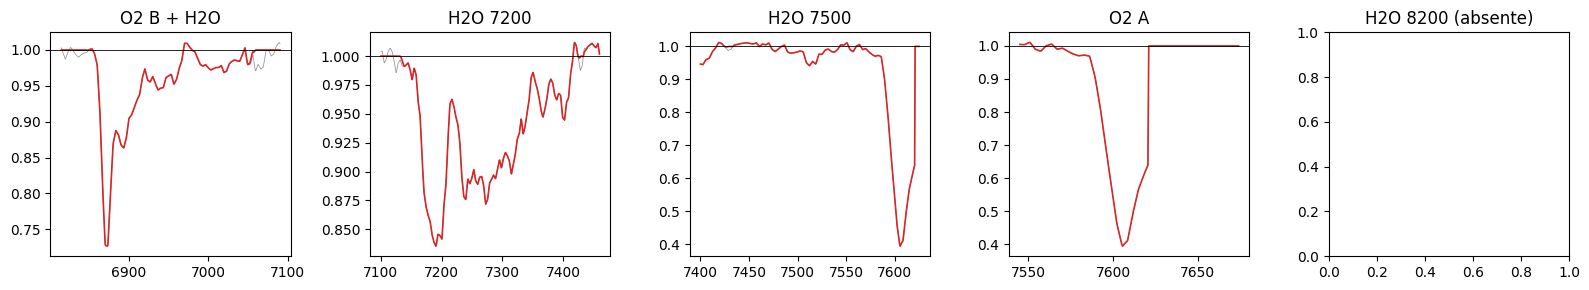

In [40]:
# ============================ GABARIT TELLURIQUE ============================
with np.errstate(all='ignore'):
    T_brut = np.where(valide, Q / Rfit, 1.0)
wgt = np.zeros(lam.size)
for _, a, b in FENETRES_TELL:
    wgt = np.maximum(wgt, np.where(np.isfinite(T_brut), fenetre_douce(lam, a, b, RAMPE_TELL) * ((lam >= a - RAMPE_TELL) & (lam <= b + RAMPE_TELL)), 0.))
T = np.clip(1.0 + wgt * (T_brut - 1.0), T_MIN, None)
T[~np.isfinite(T)] = 1.0

print("Gabarit tellurique :")
fig, axs = plt.subplots(1, len(FENETRES_TELL), figsize=(3.2 * len(FENETRES_TELL), 3), squeeze=False)
for ax, (nom, a, b) in zip(axs[0], FENETRES_TELL):
    s = (lam >= a - 40) & (lam <= b + 40)
    if not (valide & (lam >= a) & (lam <= b)).any():
        print(f"   {nom:9s} : hors du spectre ou de la référence → T = 1"); ax.set_title(nom + " (absente)"); continue
    prof = 1 - np.nanmin(T[(lam >= a) & (lam <= b)])
    print(f"   {nom:9s} : profondeur maximale {100 * prof:.1f} %")
    ax.plot(lam[s], T_brut[s], lw=.6, color='0.6'); ax.plot(lam[s], T[s], color='tab:red', lw=1.2)
    ax.axhline(1, color='k', lw=.6); ax.set_title(nom)
plt.tight_layout(); plt.show()

In [41]:
# ============================ SORTIES (même grille que le spectre ISIS) ============================
base = PREFIXE_SORTIE or os.path.splitext(os.path.basename(FICHIER_SPECTRE))[0]
fmts = formats_sortie(ext_entree, FORMAT_SORTIE)
notes = [f"Reponse instrumentale (methode Buil) - ref: {os.path.basename(FICHIER_REFERENCE)}",
         f"R_INST={R_INST} lissage={L_A:.0f}A ({MODE_LISSAGE})" + (f" (bleu {LISSAGE_BLEU_A:.0f}A <{TRANSITION_BLEU[0]:.0f}A)" if LISSAGE_BLEU_A and LISSAGE_BLEU_A < L_A else "") + " raies masquees + bandes telluriques",
         "fenetres telluriques : " + ", ".join(f"{a:.0f}-{b:.0f}" for _, a, b in FENETRES_TELL) + (f" ; sorties >= {lam[i_lo]:.0f}A" if LAM_SORTIE_MIN else ""), f"normalisation={NORMALISATION_REPONSE}"]
profils = {
    "reponse": (Rnorm, "Reponse propre (sans telluriques) : diviser le spectre par ce profil"),
    "telluric": (T, "Gabarit tellurique T (1 = pas d'absorption) : diviser le spectre par ce profil"),
    "reponse_telluric": (Rnorm * T ** ALPHA_TELLURIQUE, f"Reponse x T^{ALPHA_TELLURIQUE:g} : UNE seule division corrige reponse et telluriques"),
}
sorties = []
for nom, (y, note) in profils.items():
    neutre = 1.0 if nom == "telluric" else 0.0       # hors plage : gabarit = 1 (aucune correction), réponse = 0 comme le spectre d'entrée
    for f in fmts:
        chemin = f"{base}_{nom}.{f}"
        if HORS_BORNES == "couper":
            l_o, y_o, cr = lam[usable], y[usable], lam[i_lo]
        else:
            l_o, y_o, cr = lam, np.where(usable, y, neutre), None
        if f == 'dat':
            ecrire_dat(chemin, l_o, y_o)
        else:
            ecrire_fits(chemin, y_o, hdr, notes + [note], crval=cr)
        sorties.append(chemin)
print(f"Plage utilisable {lam[i_lo]:.1f}–{lam[i_hi]:.1f} Å : " + ("fichiers raccourcis à cette plage." if HORS_BORNES == "couper"
      else "hors plage, réponse = 0 et gabarit = 1, sur la même grille que le spectre d'entrée."))
print("Fichiers écrits :", *sorties, sep="\n   ")
print("\n→ Dans ISIS : diviser le spectre de la cible par  " + f"{base}_reponse_telluric")
try:
    from google.colab import files
    for s_ in sorties:
        files.download(s_)
except ImportError:
    pass

Plage utilisable 3600.0–7620.5 Å : fichiers raccourcis à cette plage.
Fichiers écrits :
   _hd_216916_0922_20260922_808 (3)_reponse.fits
   _hd_216916_0922_20260922_808 (3)_telluric.fits
   _hd_216916_0922_20260922_808 (3)_reponse_telluric.fits

→ Dans ISIS : diviser le spectre de la cible par  _hd_216916_0922_20260922_808 (3)_reponse_telluric


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Écart rms entre le spectre corrigé et la référence :
   points de continuum retenus pour l'ajustement : 0.54 %
   zones de raies masquées                       : 3.64 %   (différences réelles étoile / référence)
   bandes telluriques, sans gabarit T            : 12.09 %
   bandes telluriques, avec gabarit T^α          : 0.10 %   (≈ 0 par construction)
Attention : ici R et T sont tirés de cette même étoile, donc le continuum et les bandes telluriques sont accordés d'avance.
Ce contrôle montre la cohérence de la division et, aux raies, ce qui diffère réellement entre l'étoile et la référence.
Le test indépendant (autre étoile, même nuit) se fait avec FICHIER_TEST.

Contrôle de la calibration en λ : centre des raies de Balmer, mesuré − longueur d'onde de laboratoire (air) ; + = trop rouge
   raie       λ labo   spectre  référence
   Halpha     6562.8    -0.43 Å     -2.97 Å
   Hbeta      4861.3    -0.66 Å     -1.91 Å
   Hgamma     4340.5    -0.58 Å     -3.11 Å
   Hdelta     4101.7    -0.89

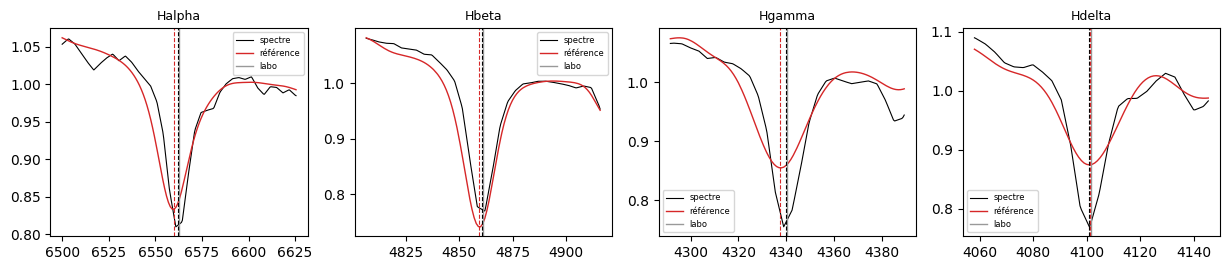

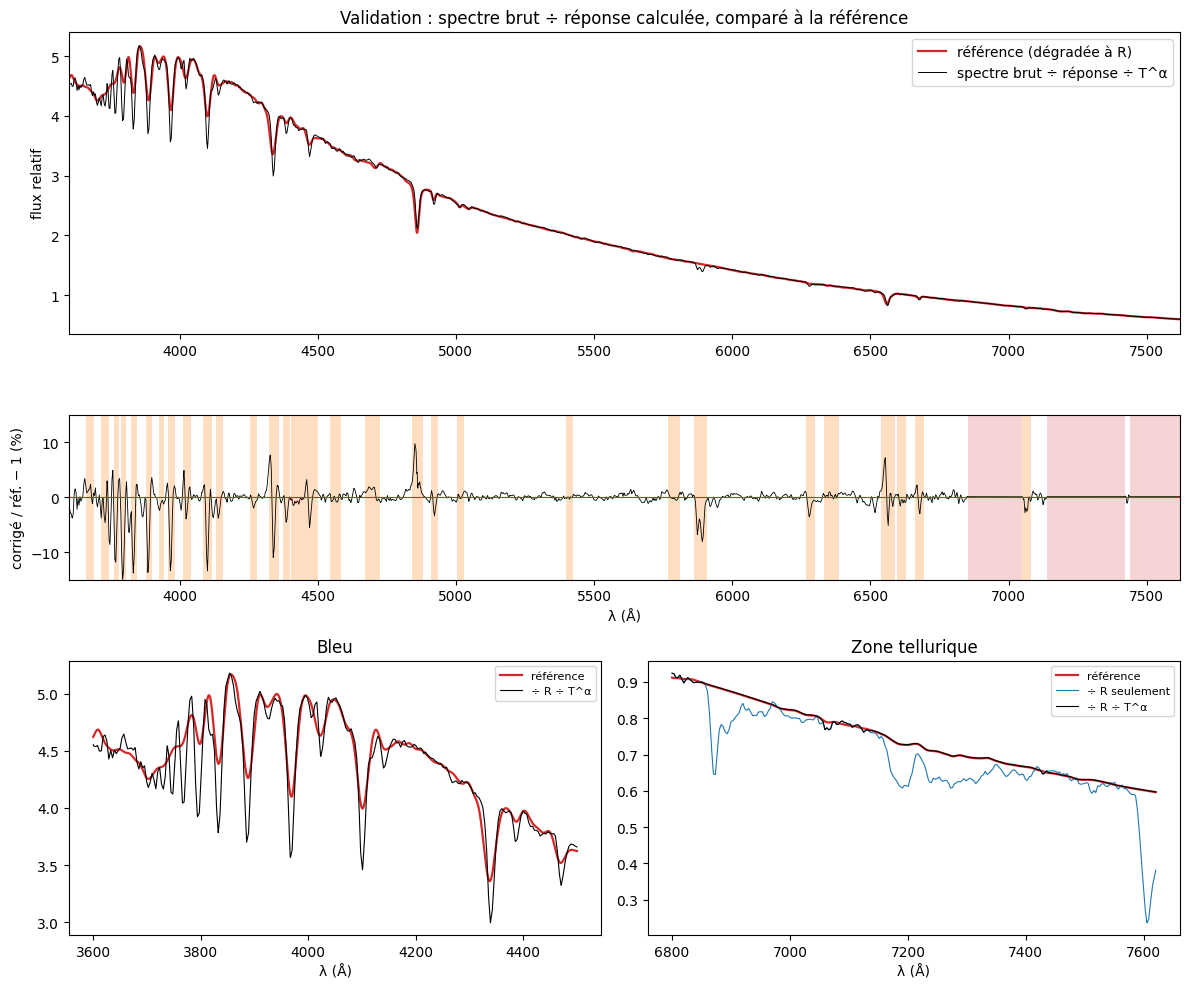

In [42]:
# ============================ VALIDATION : spectre brut ÷ réponse, comparé à la référence ============================
Rtot = Rnorm * T ** ALPHA_TELLURIQUE
with np.errstate(all='ignore'):
    corr = np.where(valide & usable, S / Rtot, np.nan)              # spectre brut ÷ réponse ÷ T^α (plage écrite seulement)
    corr_sans_T = np.where(valide & usable, S / Rnorm, np.nan)      # spectre brut ÷ réponse propre seulement
    ref_n = Fref * (np.nanmedian(corr[sel]) / np.nanmedian(Fref[sel]) if sel.any() else 1.0)   # référence au même niveau
    rap = 100 * (corr / ref_n - 1)
    rap_sans_T = 100 * (corr_sans_T / ref_n - 1)

def rms(x):
    x = x[np.isfinite(x)]
    return float(np.sqrt(np.mean(x ** 2))) if x.size else float('nan')

en_tell = m_tell & valide & usable
print("Écart rms entre le spectre corrigé et la référence :")
print(f"   points de continuum retenus pour l'ajustement : {rms(rap[w_fin > 0]):.2f} %")
print(f"   zones de raies masquées                       : {rms(rap[m_raies & valide & ~m_tell]):.2f} %   (différences réelles étoile / référence)")
if en_tell.any():
    print(f"   bandes telluriques, sans gabarit T            : {rms(rap_sans_T[en_tell]):.2f} %")
    print(f"   bandes telluriques, avec gabarit T^α          : {rms(rap[en_tell]):.2f} %   (≈ 0 par construction)")
print("Attention : ici R et T sont tirés de cette même étoile, donc le continuum et les bandes telluriques sont accordés d'avance.")
print("Ce contrôle montre la cohérence de la division et, aux raies, ce qui diffère réellement entre l'étoile et la référence.")
print("Le test indépendant (autre étoile, même nuit) se fait avec FICHIER_TEST.")
print()
controle_lambda(lam, corr, ref_n, SEUIL_LAMBDA, VITESSE_RADIALE, hdr.get('BSS_VHEL'), DECALAGE_ISIS_DEJA_APPLIQUE)
print()

fig = plt.figure(figsize=(12, 10))
gs = fig.add_gridspec(3, 2, height_ratios=[2.2, 1.2, 2])
a1 = fig.add_subplot(gs[0, :]); a2 = fig.add_subplot(gs[1, :], sharex=a1)
a3 = fig.add_subplot(gs[2, 0]); a4 = fig.add_subplot(gs[2, 1])
x0, x1 = lam[i_lo], lam[i_hi]
a1.plot(lam, ref_n, color='tab:red', lw=1.6, label="référence (dégradée à R)")
a1.plot(lam, corr, color='k', lw=.7, label="spectre brut ÷ réponse ÷ T^α")
a1.set_xlim(x0, x1); a1.legend(); a1.set_ylabel("flux relatif"); a1.set_title("Validation : spectre brut ÷ réponse calculée, comparé à la référence")
a2.plot(lam, rap, lw=.6, color='k'); a2.axhline(0, color='tab:red', lw=.8); ombrer(a2)
a2.set_ylim(-15, 15); a2.set_ylabel("corrigé / réf. − 1 (%)"); a2.set_xlabel("λ (Å)")
for ax, (u0, u1), tit in [(a3, (3600, 4500), "Bleu"), (a4, (6800, 7660), "Zone tellurique")]:
    s_ = (lam >= u0) & (lam <= u1) & valide & usable
    if not s_.any():
        ax.set_title(tit + " (hors spectre)"); continue
    ax.plot(lam[s_], ref_n[s_], color='tab:red', lw=1.6, label="référence")
    if tit == "Zone tellurique":
        ax.plot(lam[s_], corr_sans_T[s_], color='tab:blue', lw=.8, label="÷ R seulement")
    ax.plot(lam[s_], corr[s_], color='k', lw=.8, label="÷ R ÷ T^α")
    ax.set_title(tit); ax.set_xlabel("λ (Å)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [43]:
# ============================ VALIDATION INDÉPENDANTE FACULTATIVE (autre étoile) ============================
if FICHIER_TEST:
    FICHIER_TEST = trouver(None if FICHIER_TEST == "demander" else FICHIER_TEST, "▶ Choisis le spectre ISIS de test (non corrigé) :")
    if REF_TEST:
        REF_TEST = trouver(None if REF_TEST == "demander" else REF_TEST, "▶ Choisis la référence de ce spectre de test :")
    lt, ft, ht = lire_1d(FICHIER_TEST)
    Rt = np.interp(lt, lam, Rnorm); Tt = np.interp(lt, lam, T) ** ALPHA_TELLURIQUE
    corr = ft / (Rt * Tt); corr_sans_tell = ft / Rt
    n = lambda y: y / np.nanmedian(y[(lt > NORM_LAM[0]) & (lt < NORM_LAM[1])])
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={'width_ratios': [2, 1.2]})
    for ax, (x0, x1) in zip(axs, [(lt[0], lt[-1]), (6700, 7800)]):
        s = (lt >= x0) & (lt <= x1)
        ax.plot(lt[s], n(ft)[s], lw=.7, color='0.6', label="brut")
        ax.plot(lt[s], n(corr_sans_tell)[s], lw=.7, color='tab:blue', label="÷ R")
        ax.plot(lt[s], n(corr)[s], lw=.9, color='k', label="÷ R ÷ T^α")
        ax.set_xlabel("λ (Å)")
    axs[0].legend(); axs[0].set_title("Spectre de test"); axs[1].set_title("Zone tellurique")
    plt.tight_layout(); plt.show()
    if REF_TEST:
        lr, fr, _ = lire_1d(REF_TEST)
        if REF_MILIEU.lower().startswith('v'): lr = air_depuis_vide(lr)
        frd = np.interp(lt, lr, degrader(lr, fr, R_INST, REF_R_NATIVE), left=np.nan, right=np.nan)
        rap = n(corr) / n(frd)
        plt.figure(figsize=(11, 3)); plt.plot(lt, rap, lw=.7); plt.axhline(1, color='k', lw=.8)
        plt.ylim(0.7, 1.3); plt.xlabel("λ (Å)"); plt.ylabel("corrigé / référence")
        plt.title("Après correction, le rapport doit être plat (hors raies différentes)"); plt.show()
else:
    print("Pas de second spectre de test (facultatif) : renseigne FICHIER_TEST pour une validation indépendante sur une autre étoile.")

Pas de second spectre de test (facultatif) : renseigne FICHIER_TEST pour une validation indépendante sur une autre étoile.


In [44]:
# ============================ ÉTAPE 2 (facultative) : gabarit tellurique optimisé pour une cible ============================
if FICHIER_CIBLE:
    FICHIER_CIBLE = trouver(None if FICHIER_CIBLE == "demander" else FICHIER_CIBLE, "▶ Choisis le spectre ISIS de la CIBLE (brut, non corrigé de la réponse) :")
    lc, Sc, hc = lire_1d(FICHIER_CIBLE)
    dlc = float(np.median(np.diff(lc)))
    if not np.allclose(np.diff(lc), dlc, rtol=2e-3):
        raise ValueError("Grille en λ non linéaire pour la cible : rééchantillonner linéairement (ISIS) avant.")
    ext_c = os.path.splitext(FICHIER_CIBLE)[1].lower().lstrip('.')
    if ext_c not in ('fit', 'fits', 'fts'):
        ext_c = 'dat'
    if hc is None:
        hc = entete_synthetique(lc, dlc)
    ok_c = np.isfinite(Sc) & (Sc > 0)
    nn_c = np.flatnonzero(ok_c); trim_c = int(round(TRIM_BORD_A / dlc))
    bord_c = np.zeros(lc.size, bool); bord_c[nn_c[0] + trim_c: nn_c[-1] - trim_c + 1] = True
    usable_c = ok_c & bord_c & (lc >= lam[i_lo]) & (lc <= lam[i_hi])
    j = np.flatnonzero(usable_c); usable_c[j[0]: j[-1] + 1] = True
    print(f"Cible : {lc[j[0]]:.1f}–{lc[j[-1]]:.1f} Å utilisables (plage de la réponse : {lam[i_lo]:.1f}–{lam[i_hi]:.1f} Å)")
    Rc = np.interp(lc, lam, Rnorm)
    Sn = np.where(usable_c, Sc, np.nan)

    def gabarit_bande(a, b):
        w = fenetre_douce(lam, a, b, RAMPE_TELL) * ((lam >= a - RAMPE_TELL) & (lam <= b + RAMPE_TELL))
        return np.interp(lc, lam, np.clip(1.0 + w * (T_brut - 1.0), T_MIN, None))

    alphas = np.arange(0.2, 2.5001, 0.05); FL = LARGEUR_CONTINUUM_A
    T_opt = np.ones(lc.size); lignes = []; courbes = {}
    for nom, a, b in FENETRES_TELL:
        Tb = gabarit_bande(a, b)
        coeur = (lc >= a) & (lc <= b) & usable_c
        if coeur.sum() < 5:
            lignes.append((nom, None, None, None, None, "hors du spectre")); continue
        gauche = (lc >= a - RAMPE_TELL - FL) & (lc < a - RAMPE_TELL) & usable_c
        droite = (lc > b + RAMPE_TELL) & (lc <= b + RAMPE_TELL + FL) & usable_c
        if gauche.sum() < 8 and droite.sum() < 8:
            lignes.append((nom, None, None, None, None, "pas de continuum de part et d'autre")); continue
        deg = 1 if (gauche.sum() >= 8 and droite.sum() >= 8) else 0
        flanc = gauche | droite
        def rms_alpha(al):
            c = Sn / (Rc * Tb ** al)
            cont = np.polyfit(lc[flanc], c[flanc], deg)
            return float(np.sqrt(np.mean((c[coeur] / np.polyval(cont, lc[coeur]) - 1) ** 2)))
        r = np.array([rms_alpha(al) for al in alphas]); k = int(np.argmin(r)); a_fit = float(alphas[k])
        complete = (coeur.sum() >= 0.95 * ((lc >= a) & (lc <= b)).sum()) and deg == 1
        prior = (MASSE_AIR_CIBLE / MASSE_AIR_REF) if (nom.upper().startswith("O2") and MASSE_AIR_REF and MASSE_AIR_CIBLE) else 1.0
        if nom in ALPHA_IMPOSE:
            a_use, statut = float(ALPHA_IMPOSE[nom]), "imposé"
        elif complete:
            a_use, statut = a_fit, "ajusté"
            if abs(a_fit - prior) > 0.5:
                statut += " (écart > 0,5 avec l'attendu : raies stellaires dans la bande ? humidité inhabituelle ?)"
        else:
            a_use, statut = prior, f"bande partielle ou continuum d'un seul côté : ajustement indicatif ({a_fit:.2f}), non appliqué"
        T_opt *= Tb ** a_use
        lignes.append((nom, a_use, rms_alpha(0.0), rms_alpha(prior), rms_alpha(a_use), statut))
        courbes[nom] = (a, b, Tb, a_use, prior, flanc, deg)
    print("Exposant α de chaque bande pour la cible (rms du résidu dans la bande, par rapport au continuum local) :")
    print(f"   {'bande':9s} {'α utilisé':>9s} {'rms sans T':>11s} {'rms α attendu':>14s} {'rms α utilisé':>14s}   statut")
    for nom, au, r0, r1, r2, st in lignes:
        if au is None:
            print(f"   {nom:9s} {'—':>9s} {'':>11s} {'':>14s} {'':>14s}   {st}")
        else:
            print(f"   {nom:9s} {au:9.2f} {100 * r0:10.1f}% {100 * r1:13.1f}% {100 * r2:13.1f}%   {st}")
    print("   (α attendu : X_cible / X_ref pour O2 si les masses d'air sont renseignées, sinon 1 ; H2O varie avec la vapeur d'eau, α se règle sur la cible.)")

    if courbes:
        fig, axs = plt.subplots(1, len(courbes), figsize=(3.4 * len(courbes), 3.2), squeeze=False)
        for ax, (nom, (a, b, Tb, a_use, prior, flanc, deg)) in zip(axs[0], courbes.items()):
            s = (lc >= a - RAMPE_TELL - 40) & (lc <= b + RAMPE_TELL + 40) & usable_c
            ref_niv = np.nanmedian((Sn / Rc)[flanc])
            ax.plot(lc[s], (Sn / Rc)[s] / ref_niv, color='0.6', lw=.8, label="÷ R seule")
            ax.plot(lc[s], (Sn / (Rc * Tb ** prior))[s] / ref_niv, color='tab:blue', lw=.8, label=f"÷ R·T^{prior:.2f}")
            ax.plot(lc[s], (Sn / (Rc * Tb ** a_use))[s] / ref_niv, color='k', lw=.9, label=f"÷ R·T^{a_use:.2f}")
            ax.axvspan(a, b, color='tab:red', alpha=.1, lw=0); ax.set_title(nom, fontsize=9); ax.legend(fontsize=6)
        plt.tight_layout(); plt.show()

    base_c = os.path.splitext(os.path.basename(FICHIER_CIBLE))[0]
    sortie_c = {"telluric_opt": (T_opt, 1.0, "Gabarit tellurique optimise pour cette cible : diviser le spectre (deja corrige de la reponse) par ce profil"),
                "reponse_telluric_opt": (Rc * T_opt, 0.0, "Reponse x gabarit optimise pour cette cible : UNE division corrige reponse et telluriques")}
    notes_c = [f"Cible {os.path.basename(FICHIER_CIBLE)} - reponse issue de {os.path.basename(FICHIER_SPECTRE)} / ref {os.path.basename(FICHIER_REFERENCE)}",
               "alphas : " + ", ".join(f"{n}={a_:.2f}" for n, a_, *_ in lignes if a_ is not None)]
    ecrits = []
    for nom_o, (y, neutre, note) in sortie_c.items():
        for f in formats_sortie(ext_c, FORMAT_SORTIE):
            chemin = f"{base_c}_{nom_o}.{f}"
            if HORS_BORNES == "couper":
                l_o, y_o, cr = lc[usable_c], y[usable_c], lc[j[0]]
            else:
                l_o, y_o, cr = lc, np.where(usable_c, y, neutre), None
            if f == 'dat':
                ecrire_dat(chemin, l_o, y_o)
            else:
                ecrire_fits(chemin, y_o, hc, notes_c + [note], crval=cr)
            ecrits.append(chemin)
    print("Fichiers écrits :", *ecrits, sep="\n   ")
    print(f"\n→ Dans ISIS : diviser la cible par  {base_c}_reponse_telluric_opt  (une seule division), ou par {base_c}_reponse puis par {base_c}_telluric_opt")
    try:
        from google.colab import files
        for s_ in ecrits:
            files.download(s_)
    except ImportError:
        pass
else:
    print("Étape 2 facultative (gabarit optimisé pour une cible) : renseigne FICHIER_CIBLE pour la lancer.")

Étape 2 facultative (gabarit optimisé pour une cible) : renseigne FICHIER_CIBLE pour la lancer.
